In [1]:
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# ハイパーパラメータ
HIDDEN_SIZES = (128, 64)
LOSS = "l1"
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 0.1
BATCH_SIZE = 64
EPOCHS = 400
WARMUP_EPOCHS = 5
N_SPLITS = 5
CV_SEEDS = 3
N_FINAL_MODELS = 20
SEED = 2026

torch.manual_seed(SEED)
np.random.seed(SEED)
print("PyTorch", torch.__version__)

PyTorch 2.15.0


## 1. データの読み込み

In [2]:
def find_data_dir():
    # Kaggle でもローカルでも動くように探す
    needed = {"train.csv", "test.csv", "sample_submission.csv"}
    if needed.issubset(os.listdir(".")):
        return "."
    found = [d for d, _, files in os.walk("/kaggle/input") if needed.issubset(files)]
    if not found:
        raise FileNotFoundError("train.csv / test.csv / sample_submission.csv が見つかりません")
    calcofi = [d for d in found if "calcofi" in d.lower()]
    return (calcofi or found)[0]


DATA_DIR = find_data_dir()
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
print(DATA_DIR)
print("train", train.shape, " test", test.shape, " sample_submission", sample_sub.shape)

.
train (1454, 19)  test (485, 17)  sample_submission (485, 2)


## 2. 前処理


In [3]:
test_ids = test["id"].values

# train と test の共通列（ベースラインと同じ）
train_features = train.drop(columns=["Unnamed: 12", "id", "DIC"])
feature_cols = train_features.columns.intersection(test.columns)
X = train[feature_cols]
y = train["DIC"].values
X_test = test[feature_cols]

assert len(feature_cols) == 15, "モデル入力はベースラインと同じ15次元"
assert not X.isna().any().any() and not X_test.isna().any().any(), "欠損値なし"
print("入力に使う列:", list(feature_cols))

# 標準化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

X_all = torch.tensor(X_scaled, dtype=torch.float32)
y_all = torch.tensor(y, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
print("X:", tuple(X_all.shape), " y:", tuple(y_all.shape), " X_test:", tuple(X_test_t.shape))

入力に使う列: ['Lat_Dec', 'Lon_Dec', 'NO2uM', 'NO3uM', 'NH3uM', 'R_TEMP', 'R_Depth', 'R_Sal', 'R_DYNHT', 'R_Nuts', 'R_Oxy_micromol.Kg', 'PO4uM', 'SiO3uM', 'Salinity1', 'Temperature_degC']
X: (1454, 15)  y: (1454,)  X_test: (485, 15)


## 3. モデル

ベースラインと同じ

In [4]:
class FeedForwardNet(nn.Module):
    def __init__(self, input_size, hidden_sizes=HIDDEN_SIZES):
        super().__init__()
        layers = []
        in_features = input_size
        for hidden in hidden_sizes:
            layers.append(nn.Linear(in_features, hidden))
            layers.append(nn.ReLU())
            in_features = hidden
        layers.append(nn.Linear(in_features, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


example = FeedForwardNet(X_all.shape[1])
print(example)
print("パラメータ数:", sum(p.numel() for p in example.parameters()))

FeedForwardNet(
  (net): Sequential(
    (0): Linear(in_features=15, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
パラメータ数: 10369


## 4. 学習


In [5]:
def rmse(pred, target):
    return float(np.sqrt(np.mean((pred - target) ** 2)))


def train_fnn(X_tr, y_tr, seed, loss_name=LOSS, X_val=None, y_val=None):
    torch.manual_seed(seed)
    shuffle_rng = torch.Generator().manual_seed(seed)

    # 目的変数の標準化
    y_mean, y_std = y_tr.mean(), y_tr.std()
    t_tr = (y_tr - y_mean) / y_std

    model = FeedForwardNet(X_tr.shape[1])
    weights = [p for name, p in model.named_parameters() if name.endswith("weight")]
    biases = [p for name, p in model.named_parameters() if name.endswith("bias")]
    optimizer = torch.optim.AdamW(
        [{"params": weights, "weight_decay": WEIGHT_DECAY}, {"params": biases, "weight_decay": 0.0}],
        lr=LEARNING_RATE,
    )
    criterion = nn.L1Loss() if loss_name == "l1" else nn.MSELoss()

    n = len(X_tr)
    steps_per_epoch = math.ceil(n / BATCH_SIZE)
    total_steps = EPOCHS * steps_per_epoch
    warmup_steps = WARMUP_EPOCHS * steps_per_epoch

    def lr_factor(step):
        if step < warmup_steps:  # ウォームアップ
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / (total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * progress))  # コサインアニーリング

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

    def predict(X_new):
        model.eval()
        with torch.no_grad():
            return (model(X_new) * y_std + y_mean).numpy()  # 元の単位（µmol/kg）に戻す

    history = []
    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(n, generator=shuffle_rng)
        for start in range(0, n, BATCH_SIZE):
            idx = perm[start:start + BATCH_SIZE]
            loss = criterion(model(X_tr[idx]), t_tr[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
        if X_val is not None and (epoch + 1) % 5 == 0:
            history.append((epoch + 1, rmse(predict(X_tr), y_tr.numpy()), rmse(predict(X_val), y_val.numpy())))
    return predict, history

## 5. 5-fold 交差検証

MSE と L1 を比べる。

In [6]:
def run_cv(loss_name, n_seeds):
    kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    oof = np.zeros((n_seeds, len(y)))
    histories = []
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X_scaled)):
        tr_t, va_t = torch.as_tensor(tr_idx), torch.as_tensor(va_idx)
        for s in range(n_seeds):
            predict, history = train_fnn(X_all[tr_t], y_all[tr_t], seed=SEED + 100 * fold + s,
                                         loss_name=loss_name, X_val=X_all[va_t], y_val=y_all[va_t])
            oof[s, va_idx] = predict(X_all[va_t])
            histories.append(history)
    return oof, np.array(histories)


start_time = time.time()
oof_mse, hist_mse = run_cv("mse", 1)
oof_l1, hist_l1 = run_cv("l1", CV_SEEDS)

cv_mse = rmse(oof_mse[0], y)
cv_l1_single = float(np.mean([rmse(o, y) for o in oof_l1]))
cv_l1_avg = rmse(oof_l1.mean(axis=0), y)
print(f"MSE 損失・単体モデル          : CV RMSE = {cv_mse:.3f}")
print(f"L1 損失・単体モデル           : CV RMSE = {cv_l1_single:.3f}  （{CV_SEEDS} シードの平均）")
print(f"L1 損失・{CV_SEEDS} モデルの平均       : CV RMSE = {cv_l1_avg:.3f}")
print("（参考）ベースラインの Public Score = 6.08783（test での値。CV とは評価データが違うので目安）")
print(f"所要時間 {time.time() - start_time:.0f} 秒")

MSE 損失・単体モデル          : CV RMSE = 5.376
L1 損失・単体モデル           : CV RMSE = 5.087  （3 シードの平均）
L1 損失・3 モデルの平均       : CV RMSE = 5.030
（参考）ベースラインの Public Score = 6.08783（test での値。CV とは評価データが違うので目安）
所要時間 67 秒


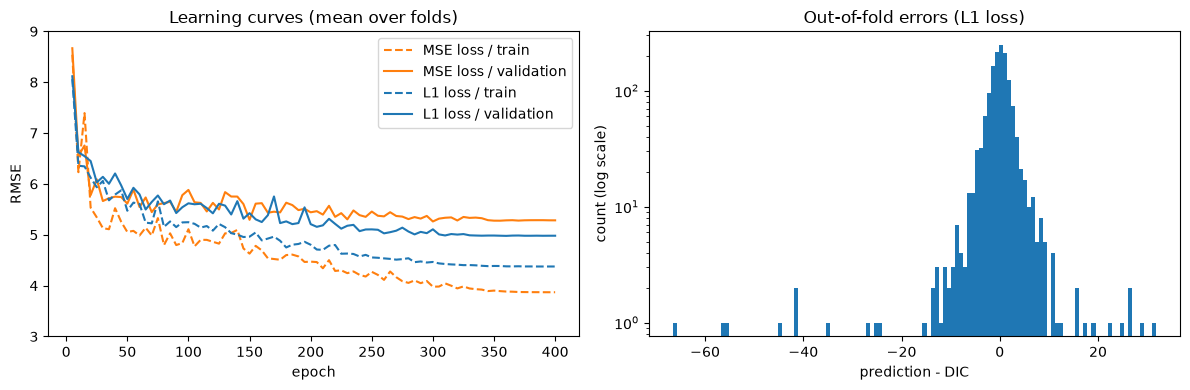

絶対誤差：中央値 1.35 / 90%点 4.90 / 最大 66.51
誤差の大きい上位 1%（14 件）が二乗誤差の合計に占める割合：61%
上位 1% を除いた RMSE：3.151


In [7]:
# 学習曲線と誤差の分布
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for hist, name, color in [(hist_mse, "MSE loss", "tab:orange"), (hist_l1, "L1 loss", "tab:blue")]:
    mean_hist = hist.mean(axis=0)
    axes[0].plot(mean_hist[:, 0], mean_hist[:, 1], color=color, linestyle="--", label=f"{name} / train")
    axes[0].plot(mean_hist[:, 0], mean_hist[:, 2], color=color, label=f"{name} / validation")
axes[0].set_ylim(3, 9)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Learning curves (mean over folds)")
axes[0].legend()

residual = oof_l1.mean(axis=0) - y
axes[1].hist(residual, bins=120, color="tab:blue")
axes[1].set_yscale("log")
axes[1].set_xlabel("prediction - DIC")
axes[1].set_ylabel("count (log scale)")
axes[1].set_title("Out-of-fold errors (L1 loss)")
plt.tight_layout()
plt.show()

abs_err = np.sort(np.abs(residual))[::-1]
n_top = len(abs_err) // 100
print(f"絶対誤差：中央値 {np.median(abs_err):.2f} / 90%点 {np.quantile(abs_err, 0.9):.2f} / 最大 {abs_err[0]:.2f}")
print(f"誤差の大きい上位 1%（{n_top} 件）が二乗誤差の合計に占める割合：{(abs_err[:n_top] ** 2).sum() / (abs_err ** 2).sum():.0%}")
print(f"上位 1% を除いた RMSE：{np.sqrt(np.mean(abs_err[n_top:] ** 2)):.3f}")

L1 のほうが CV RMSE が低かったので L1 を使う。誤差の大きい一部のサンプルが二乗誤差の大半を占めている。

## 6. 全データで再学習して予測

初期値を変えた FFNN を 20 個学習して平均をとる。

In [8]:
start_time = time.time()
test_preds = []
for i in range(N_FINAL_MODELS):
    predict, _ = train_fnn(X_all, y_all, seed=SEED + 1000 + i)
    test_preds.append(predict(X_test_t))
    if (i + 1) % 10 == 0:
        print(f"{i + 1}/{N_FINAL_MODELS} モデル学習済み（{time.time() - start_time:.0f} 秒）")

test_preds = np.stack(test_preds).astype(np.float64)
final_pred = test_preds.mean(axis=0)
spread = test_preds.std(axis=0)
print(f"モデル間の予測のばらつき（標準偏差）：平均 {spread.mean():.3f} / 最大 {spread.max():.3f}")
print(f"予測値の範囲：{final_pred.min():.1f} 〜 {final_pred.max():.1f}（訓練データの DIC：{y.min():.1f} 〜 {y.max():.1f}）")

10/20 モデル学習済み（38 秒）


20/20 モデル学習済み（75 秒）
モデル間の予測のばらつき（標準偏差）：平均 0.653 / 最大 4.751
予測値の範囲：1982.6 〜 2364.9（訓練データの DIC：1948.8 〜 2367.8）


In [ ]:
submission = pd.DataFrame({"id": test_ids, "DIC": final_pred})

# 提出ファイルの形式チェック
assert submission.shape == sample_sub.shape
assert (submission["id"].values == sample_sub["id"].values).all()
assert np.isfinite(submission["DIC"]).all()

submission.to_csv("submission.csv", index=False)
submission.head()

,id,DIC
0,1455,2172.403467
1,1456,2194.483691
2,1457,2326.679187
3,1458,1989.724890
4,1459,2151.519775


In [ ]:
# score: 4.49282